# 🇮🇩 Kombinasi Regex & Normalisasi Bahasa Indonesia Terpadu (`IndonesianRegexCombinator`)
**Aturan Emas Preprocessing Teks Bahasa Indonesia di Kompetisi GEMASTIK:**
> *"Extract Signal First, Normalize Second, and NEVER Delete Negation Words!"*

Mengapa banyak peserta kehilangan 3%–8% skor F1 saat membersihkan teks Bahasa Indonesia?
1. **Menghapus tanda seru/kapitalisasi terlalu cepat:** Padahal kalimat `PARAH BANGET!!!` punya emosi yang jauh lebih kuat daripada `parah banget`.
2. **Merusak kata ulang angka (`kata2`) karena menghapus angka:** Jika angka dihapus sembarangan, `jalan2` dan `aturan2` berubah menjadi `jalan` dan `aturan`.
3. **Menghapus kata negasi saat stopword removal:** Daftar stopword standar sering menghapus kata `tidak`, `bukan`, `jangan`, `belum`, sehingga kalimat `tidak puas` berubah menjadi `puas` (label terbalik 180 derajat!).

### 🧱 7 Lego Bricks pada `IndonesianRegexCombinator`:
- **Brick 1 (`extract_pre_clean_signals`):** Mengekstrak **12 fitur numerik/rasio** sebelum teks dibersihkan.
- **Brick 2 (`mask_entities`):** Mengubah URL, `@user`, `#hashtag`, nominal `Rp 250.000`, dan nomor telepon menjadi token semantik `<URL>`, `<USER>`, `<MONEY>`, `<PHONE>`.
- **Brick 3 (`expand_reduplication`):** Mengubah `error2` $\to$ `error-error`, `tiba2` $\to$ `tiba-tiba`.
- **Brick 4 (`normalize_elongation`):** Mengubah `paraaaahhh` $\to$ `parah`, `baguuusss` $\to$ `bagus`.
- **Brick 5 (`normalize_slang`):** Menyatukan 180+ kata slang & negasi (`gk`, `ga`, `gak`, `enggak`, `tdk`, `kagak` $\to$ `tidak`; `bgt` $\to$ `banget`).
- **Brick 6 (`normalize_colloquial_affixes`):** Mengubah akhiran percakapan `-in` (`benerin` $\to$ `benarkan`, `nyebelin` $\to$ `menyebalkan`).
- **Brick 7 (`remove_stopwords_negation_safe`):** Menghapus kata hubung tak bermakna namun **100% melindungi kata negasi & eskalator emosi**.

In [1]:
# ==============================================================================
# ⚙️ MASTER USER CONFIGURATION (PUSAT KENDALI REGEX KOMBINASI BAHASA INDONESIA)
# ==============================================================================
TRAIN_PATH                        = '../demo_data/train_chained_soal2.csv'
TEXT_COL                          = 'text'
TARGET_COL                        = 'stage1_pred_label'

# Nyalakan / Matikan 7 Lego Bricks sesuai karakteristik dataset Hari-H:
BRICK_1_EXTRACT_PRE_CLEAN_SIGNALS = True   # Ekstrak 12 fitur numerik sebelum teks dibersihkan
BRICK_2_MASK_ENTITIES             = True   # Ubah URL, @user, Rp, No HP jadi token <URL>, <MONEY>
BRICK_3_EXPAND_REDUPLICATION      = True   # Ubah kata2 -> kata-kata
BRICK_4_NORMALIZE_ELONGATION      = True   # Ubah banguuuusss -> bagus
BRICK_5_NORMALIZE_SLANG           = True   # Konversi 180+ slang & unifikasi negasi -> 'tidak'
BRICK_6_COLLOQUIAL_AFFIXES        = True   # Normalisasi imbuhan lisan (nyebelin -> menyebalkan)
BRICK_7_NEGATION_SAFE_STOPWORDS   = False  # Set True untuk TF-IDF/LSA, False untuk IndoBERT
print('✅ Konfigurasi IndonesianRegexCombinator berhasil dimuat!')

✅ Konfigurasi IndonesianRegexCombinator berhasil dimuat!


In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from smart_loader import load_raw_format_to_df, evaluate_classification_switchboard
from indonesian_regex_combinator import IndonesianRegexCombinator

MODELS_DIR = Path('models')
MODELS_DIR.mkdir(parents=True, exist_ok=True)

df = load_raw_format_to_df(TRAIN_PATH)
combinator = IndonesianRegexCombinator(
    extract_pre_clean_signals=BRICK_1_EXTRACT_PRE_CLEAN_SIGNALS,
    mask_entities=BRICK_2_MASK_ENTITIES,
    expand_reduplication=BRICK_3_EXPAND_REDUPLICATION,
    normalize_elongation=BRICK_4_NORMALIZE_ELONGATION,
    normalize_slang=BRICK_5_NORMALIZE_SLANG,
    normalize_colloquial_affixes=BRICK_6_COLLOQUIAL_AFFIXES,
    remove_stopwords_negation_safe=BRICK_7_NEGATION_SAFE_STOPWORDS,
)

df, rx_feature_cols = combinator.fit_transform_df(df, TEXT_COL, prefix='rx_')

print('🔍 Perbandingan Teks Asli vs Hasil Kombinasi Regex Bahasa Indonesia:\n')
for i in range(4):
    print(f'[{i+1}] RAW   : {df[TEXT_COL].iloc[i]}')
    print(f'    CLEAN : {df[TEXT_COL + "_clean"].iloc[i]}\n')

🔍 Perbandingan Teks Asli vs Hasil Kombinasi Regex Bahasa Indonesia:

[1] RAW   : PARAH BANGET!! Aplikasi pajak daerah error2 terus dr pagi, ga bisa login padahal udh bayar Rp 250.000 #KecewaBerat @pemda_id (Ref:0)
    CLEAN : buruk banget!! aplikasi pajak daerah error-error terus dari pagi, tidak bisa login padahal sudah bayar [MONEY] kecewaberat [USER] (ref:0)

[2] RAW   : Jujur kecewa bgt sm pelayanan loket 3, petugasnya jutek2 & ga ramah sama sekali kpd lansia!! Tolong dievaluasi segera! (Ref:1)
    CLEAN : jujur kecewa banget sama pelayanan loket 3, petugasnya jutek-jutek & tidak ramah sama sekali kepada lansia!! tolong dievaluasi segera! (ref:1)

[3] RAW   : Kenapa server pendaftaran beasiswa down mulu sih?? Padahal batas upload berkas tinggal 2 jam lg lhooo 😭😭 (Ref:2)
    CLEAN : mengapa server pendaftaran beasiswa down mulu sih?? padahal batas upload berkas tinggal 2 jam lagi lho 😭😭 (ref:2)

[4] RAW   : Pungutan biaya admin Rp 50rb tanpa kuitansi resmi di kantor kecamatan itu be

,rx_caps_ratio,rx_allcaps_words,rx_exclamation_count,rx_question_count,rx_angka2_redup_count,rx_char_elongation_count,rx_laugh_token_count,rx_url_mention_count,rx_money_mention_count,rx_negation_word_count,rx_slang_word_count,rx_emoji_non_ascii_count,rx_avg_word_len
stage1_pred_label,,,,,,,,,,,,,
negatif,0.044,0.400,1.400,0.80,0.4,0.2,0.0,0.2,0.4,0.600,3.6,0.400,5.379
netral,0.034,0.500,0.000,0.25,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.000,6.476
positif,0.048,1.333,1.333,0.00,0.0,0.0,0.0,0.0,0.0,0.667,3.0,0.667,5.113


C:\Users\yasse\AppData\Local\Temp\ipykernel_30324\4123129807.py:12: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\yasse\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


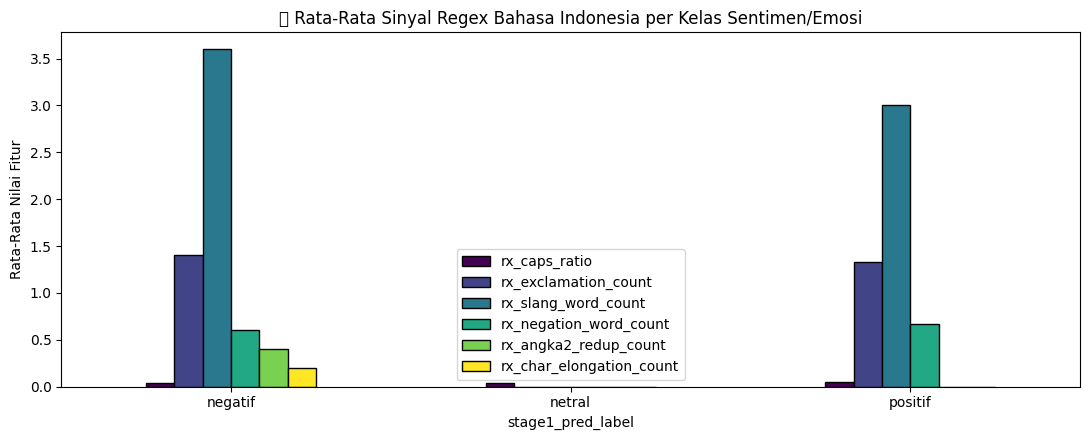

✅ Metadata analisis IndonesianRegexCombinator disimpan di models/04_indo_regex_config_results.json


In [3]:
# ==============================================================================
# 📊 VISUALISASI 12 SINYAL REGEX PRE-CLEAN TERHADAP KELAS TARGET
# ==============================================================================
summary_by_class = df.groupby(TARGET_COL)[rx_feature_cols].mean()
display(summary_by_class.round(3))

key_signals = ['rx_caps_ratio', 'rx_exclamation_count', 'rx_slang_word_count', 'rx_negation_word_count', 'rx_angka2_redup_count', 'rx_char_elongation_count']
ax = summary_by_class[key_signals].plot(kind='bar', figsize=(11, 4.5), colormap='viridis', edgecolor='black')
ax.set_title('📊 Rata-Rata Sinyal Regex Bahasa Indonesia per Kelas Sentimen/Emosi')
ax.set_ylabel('Rata-Rata Nilai Fitur')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

meta_payload = {
    'notebook': '04_indonesian_regex_combinator_pipeline',
    'extracted_regex_features': rx_feature_cols,
    'num_regex_features': len(rx_feature_cols),
    'all_validation_metrics': {'num_regex_features': float(len(rx_feature_cols))},
}
with open(MODELS_DIR / '04_indo_regex_config_results.json', 'w', encoding='utf-8') as f:
    json.dump(meta_payload, f, indent=2)
print('✅ Metadata analisis IndonesianRegexCombinator disimpan di models/04_indo_regex_config_results.json')